FIRST-ORDER LOGIC (FOL) RESOLUTION PROVER (CNF)
1. Variables start with lowercase (e.g., x, y, z)
2. Constants start with UPPERCASE (e.g., John, Peanuts, Anil)
3. Use '~' for NOT and '|' for OR

Press 1 for Default Example (John & Peanuts) or 2 for custom problem: 2

Enter Knowledge Base clauses in CNF (type 'done' when finished):
Clause 1:  ~allergies(x) | sneezes(x)
Clause 2: ~livesWith(y, z) | ~cat(z) | ~allergicToCats(y) | allergies(y)
Clause 3: cat(Tom)
Clause 4: allergicToCats(Mary)
Clause 5:  livesWith(Mary, Tom)
Clause 6: done

Enter Query to prove: sneezes(Mary)


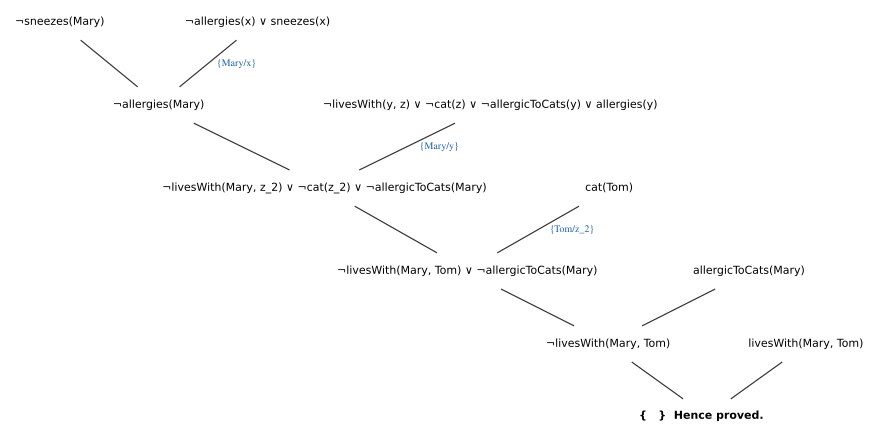

In [10]:
import heapq
import re
from graphviz import Digraph
from IPython.display import display


class Literal:

  def __init__(self, predicate, args, negated=False):
    self.predicate = predicate
    self.args = args
    self.negated = negated

  def negate(self):
    return Literal(self.predicate, self.args[:], not self.negated)

  def __repr__(self):
    neg_str = "¬" if self.negated else ""
    return f"{neg_str}{self.predicate}({', '.join(self.args)})"

  def __eq__(self, other):
    return (
        self.predicate == other.predicate
        and self.args == other.args
        and self.negated == other.negated
    )

  def __hash__(self):
    return hash((self.predicate, tuple(self.args), self.negated))


def is_variable(term):
  return isinstance(term, str) and term.islower()


def base_name(var):
  return re.sub(r"_\d+$", "", var)


def parse_literal(lit_str):
  lit_str = lit_str.strip()
  negated = False
  if lit_str.startswith("~") or lit_str.startswith("¬"):
    negated = True
    lit_str = lit_str[1:].strip()

  match = re.match(r"([A-Za-z0-9_]+)\(([^)]+)\)", lit_str)
  if not match:
    raise ValueError(f"Invalid literal format: '{lit_str}'")

  predicate = match.group(1).strip()
  args = [arg.strip() for arg in match.group(2).split(",")]
  return Literal(predicate, args, negated)


def parse_clause(clause_str):
  parts = re.split(r"\s*\|\s*|\s+V\s+", clause_str.strip())
  return [parse_literal(p) for p in parts if p.strip()]


def format_clause(clause):
  if not clause:
    return "{   }  Hence proved."
  cleaned = []
  for lit in clause:
    clean_args = [
        base_name(arg) if is_variable(arg) else arg for arg in lit.args
    ]
    cleaned.append(str(Literal(lit.predicate, clean_args, lit.negated)))
  return " ∨ ".join(cleaned)


def canonical_form(clause):
  mapping = {}
  counter = 0
  canon = []
  for lit in sorted(
      clause, key=lambda l: (l.predicate, l.negated, len(l.args))
  ):
    new_args = []
    for arg in lit.args:
      if is_variable(arg):
        if arg not in mapping:
          mapping[arg] = f"v{counter}"
          counter += 1
        new_args.append(mapping[arg])
      else:
        new_args.append(arg)
    canon.append((lit.predicate, lit.negated, tuple(new_args)))
  return tuple(sorted(canon))


def is_tautology(clause):
  for i in range(len(clause)):
    for j in range(i + 1, len(clause)):
      if (
          clause[i].predicate == clause[j].predicate
          and clause[i].args == clause[j].args
          and clause[i].negated != clause[j].negated
      ):
        return True
  return False


def unify_var(var, x, theta):
  if var in theta:
    return unify(theta[var], x, theta)
  elif is_variable(x) and x in theta:
    return unify(var, theta[x], theta)
  elif occurs_check(var, x, theta):
    return None
  else:
    theta[var] = x
    return theta


def occurs_check(var, x, theta):
  if var == x:
    return True
  elif is_variable(x) and x in theta:
    return occurs_check(var, theta[x], theta)
  return False


def unify(x, y, theta):
  if theta is None:
    return None
  elif x == y:
    return theta
  elif is_variable(x):
    return unify_var(x, y, theta)
  elif is_variable(y):
    return unify_var(y, x, theta)
  elif isinstance(x, list) and isinstance(y, list):
    if len(x) != len(y):
      return None
    for a, b in zip(x, y):
      theta = unify(a, b, theta)
      if theta is None:
        return None
    return theta
  else:
    return None


def apply_substitution(clause, theta):
  new_clause = []
  for lit in clause:
    new_args = []
    for arg in lit.args:
      val = arg
      while is_variable(val) and val in theta:
        val = theta[val]
      new_args.append(val)
    new_lit = Literal(lit.predicate, new_args, lit.negated)
    if new_lit not in new_clause:
      new_clause.append(new_lit)
  return new_clause


def standardize_variables(clause, counter):
  mapping = {}
  new_clause = []
  for lit in clause:
    new_args = []
    for arg in lit.args:
      if is_variable(arg):
        if arg not in mapping:
          mapping[arg] = f"{arg}_{counter}"
        new_args.append(mapping[arg])
      else:
        new_args.append(arg)
    new_clause.append(Literal(lit.predicate, new_args, lit.negated))
  return new_clause


def resolve(ci, cj):
  resolvents = []
  for li in ci:
    for lj in cj:
      if li.predicate == lj.predicate and li.negated != lj.negated:
        theta = unify(li.args, lj.args, {})
        if theta is not None:
          new_ci = [l for l in ci if l != li]
          new_cj = [l for l in cj if l != lj]
          combined = apply_substitution(new_ci + new_cj, theta)
          resolvents.append((combined, theta))
  return resolvents


def draw_resolution_tree(clauses_info, goal_idx):
  dot = Digraph(format="png")
  dot.attr(rankdir="TB", splines="line", nodesep="0.6", ranksep="0.5")
  dot.attr(
      "node", shape="plaintext", fontname="DejaVu Sans", fontsize="11"
  )
  dot.attr("edge", arrowhead="none", color="#333333", penwidth="1.2")

  visited = set()

  def add_nodes(idx):
    if idx in visited:
      return
    visited.add(idx)

    info = clauses_info[idx]
    label = format_clause(info["clause"])
    if idx == goal_idx:
      dot.node(str(idx), f"<<B>{label}</B>>")
    else:
      dot.node(str(idx), label)

    if info["parents"] is not None:
      p1, p2 = info["parents"]
      if clauses_info[p1]["parents"] is not None:
        left, right = p1, p2
      else:
        left, right = p2, p1

      add_nodes(left)
      add_nodes(right)

      sub = info["sub"]
      sub_label = ""
      if sub:
        pairs = [f"{v}/{k}" for k, v in sub.items()]
        sub_label = "  {" + ", ".join(pairs) + "}"

      dot.edge(str(left), str(idx))
      dot.edge(str(right), str(idx), label=sub_label, fontsize="10", fontcolor="#1a5fb4")

  add_nodes(goal_idx)
  display(dot)


def fol_resolution(kb_clauses, query_literal):
  clauses_info = []
  seen_canons = set()
  sos_indices = set()

  for idx, c in enumerate(kb_clauses):
    std_c = standardize_variables(c, idx + 1)
    canon = canonical_form(std_c)
    if canon not in seen_canons:
      seen_canons.add(canon)
      clauses_info.append({
          "clause": std_c,
          "parents": None,
          "sub": None,
          "source": "Given KB",
      })

  neg_query = [query_literal.negate()]
  query_idx = len(clauses_info)
  clauses_info.append({
      "clause": neg_query,
      "parents": None,
      "sub": None,
      "source": "Negated Query",
  })
  seen_canons.add(canonical_form(neg_query))
  sos_indices.add(query_idx)

  pq = []
  for i in range(query_idx):
    priority = len(clauses_info[i]["clause"]) + len(neg_query)
    heapq.heappush(pq, (priority, i, query_idx))

  visited_pairs = set()

  while pq:
    _, i, j = heapq.heappop(pq)
    pair = (min(i, j), max(i, j))
    if pair in visited_pairs:
      continue
    visited_pairs.add(pair)

    resolvents = resolve(clauses_info[i]["clause"], clauses_info[j]["clause"])
    for resolvent, theta in resolvents:
      if is_tautology(resolvent):
        continue

      clean_theta = {}
      for k, v in theta.items():
        val = v
        while is_variable(val) and val in theta:
          val = theta[val]
        clean_k = base_name(k)
        clean_v = base_name(val) if is_variable(val) else val
        if clean_k != clean_v:
          clean_theta[clean_k] = clean_v

      if len(resolvent) == 0:
        goal_idx = len(clauses_info)
        clauses_info.append({
            "clause": [],
            "parents": (i, j),
            "sub": clean_theta,
            "source": "Derived",
        })
        draw_resolution_tree(clauses_info, goal_idx)
        return True

      canon = canonical_form(resolvent)
      if canon not in seen_canons:
        seen_canons.add(canon)
        new_idx = len(clauses_info)
        std_res = standardize_variables(resolvent, new_idx + 1)
        clauses_info.append({
            "clause": std_res,
            "parents": (i, j),
            "sub": clean_theta,
            "source": "Derived",
        })
        sos_indices.add(new_idx)

        for k in range(new_idx):
          if k in sos_indices or k < query_idx:
            priority = len(clauses_info[k]["clause"]) + len(std_res)
            heapq.heappush(pq, (priority, k, new_idx))

  print("\nCannot prove: Empty clause could not be derived.")
  return False


def run_solver():
  print("FIRST-ORDER LOGIC (FOL) RESOLUTION PROVER (CNF)")
  print("1. Variables start with lowercase (e.g., x, y, z)")
  print("2. Constants start with UPPERCASE (e.g., John, Peanuts, Anil)")
  print("3. Use '~' for NOT and '|' for OR")

  choice = input(
      "\nPress 1 for Default Example (John & Peanuts) or 2 for custom problem: "
  ).strip()

  if choice == "1":
    raw_kb = [
        "~food(x) | likes(John, x)",
        "food(Apple)",
        "food(Vegetables)",
        "~eats(y, z) | killed(y) | food(z)",
        "eats(Anil, Peanuts)",
        "alive(Anil)",
        "~eats(Anil, w) | eats(Harry, w)",
        "killed(g) | alive(g)",
        "~alive(k) | ~killed(k)",
    ]
    raw_query = "likes(John, Peanuts)"

  else:
    print("\nEnter Knowledge Base clauses in CNF (type 'done' when finished):")
    raw_kb = []
    while True:
      line = input(f"Clause {len(raw_kb)+1}: ").strip()
      if line.lower() == "done":
        break
      if line:
        raw_kb.append(line)

    raw_query = input("\nEnter Query to prove: ").strip()

  try:
    kb_clauses = [parse_clause(c) for c in raw_kb]2
    query_lit = parse_literal(raw_query)
    fol_resolution(kb_clauses, query_lit)
  except Exception as e:
    print(f"\nError parsing input: {e}")


run_solver()
